# 03 Directory of visualizations (Lecture 5)

Lecture 5 sorts charts by what the data is: amounts, distributions,
proportions, x-y relationships, geospatial, and uncertainty. One
chart per family, each picked for a question about the 2026 season.
Color choices carry over from 02 (Okabe-Ito top 4, gray for the rest).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from scipy import stats
from f1viz import load, save, FIGS, OKABE_ITO, TOP4, GRAY, DARK

res = load("results")
pit = load("pit_stops")
ts = load("team_standings")
cal = load("calendar")
LAST = res["round"].max()
ABBR = ["AUS", "CHN", "JPN", "MIA", "CAN", "MON", "BAR", "AUT",
        "GBR", "BEL", "HUN", "NED", "ITA", "ESP", "AZE"]

## 5.1 Amounts: who has the most points?

Points per team is one number per category, so bars. Horizontal so
the team names read easily, sorted so the ranking is instant. One
color, because color would not add information here.

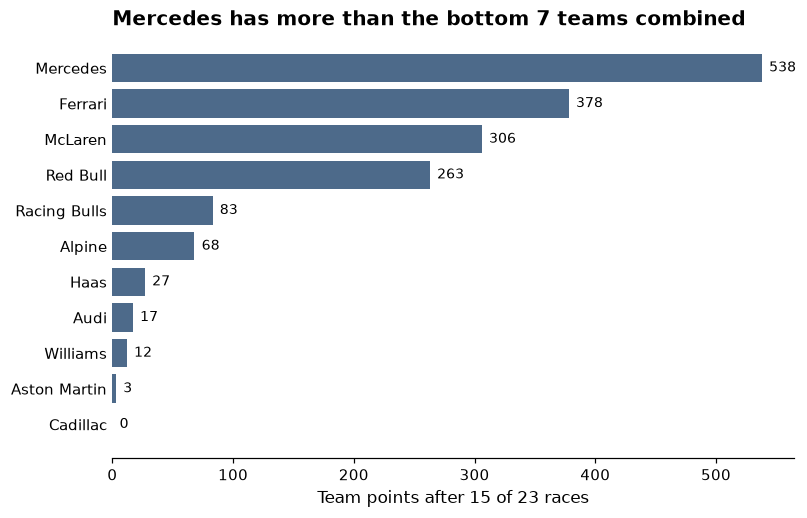

In [2]:
final = (ts[ts["round"] == LAST].sort_values("points")
         .set_index("team")["points"])

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(final.index, final.values, color="#4D6A8A")
for team, v in final.items():
    ax.text(v + 6, team, f"{v:.0f}", va="center", fontsize=9)
ax.set(xlabel="Team points after 15 of 23 races",
       title="Mercedes has more than the bottom 7 teams combined")
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
save(fig, "fig07_amounts_team_points")
plt.show()

In [3]:
bottom7 = final.iloc[:7].sum()
print("Mercedes", final["Mercedes"], "| bottom 7 combined", bottom7)

Mercedes 538.0 | bottom 7 combined 210.0


**Result:** Mercedes 538, then Ferrari 378, McLaren 306, Red Bull
263. Then a cliff: Racing Bulls has 83 and the bottom 7 combined
have 210.

**Inference:** 2026 is a 4 team championship with a clear leader.
The cliff after P4 is the most important thing on this chart.

## 5.2 Distributions: how long is a pit stop?

469 pit stops. We want to compare the spread across 15 races, which
is the "many distributions at once" case, so boxplots with the raw
stops drawn on top (a strip chart) so no data is hidden. Sorted by
median.

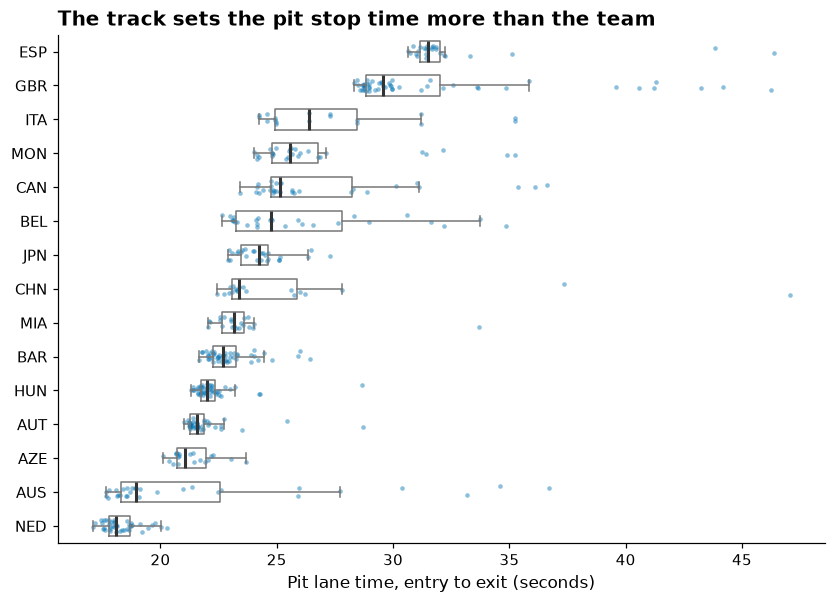

In [4]:
order = (pit.groupby("round")["seconds"].median()
         .sort_values().index)
data = [pit.loc[pit["round"] == r, "seconds"] for r in order]

fig, ax = plt.subplots(figsize=(9, 6))
ax.boxplot(data, orientation="horizontal", widths=0.6, showfliers=False,
           medianprops=dict(color=DARK, lw=2),
           boxprops=dict(color="#777777"),
           whiskerprops=dict(color="#777777"),
           capprops=dict(color="#777777"))
rng = np.random.default_rng(1)
for i, d in enumerate(data, start=1):
    y = i + rng.uniform(-0.18, 0.18, len(d))
    ax.scatter(d, y, s=9, color=OKABE_ITO["blue"], alpha=0.45,
               lw=0)
ax.set_yticks(range(1, len(order) + 1),
              [ABBR[r - 1] for r in order])
ax.set(xlabel="Pit lane time, entry to exit (seconds)",
       title="The track sets the pit stop time more than the team")
save(fig, "fig08_distributions_pit_times")
plt.show()

In [5]:
med = pit.groupby("round")["seconds"].median()
print("fastest race median", med.min(), ABBR[med.idxmin() - 1])
print("slowest race median", med.max(), ABBR[med.idxmax() - 1])
spread = pit.groupby("round")["seconds"].apply(
    lambda s: s.quantile(.75) - s.quantile(.25))
print("typical IQR within a race", spread.median().round(2))

fastest race median 18.074 NED
slowest race median 31.483 ESP
typical IQR within a race 1.25


**Result:** the typical pit stop ranges from 18 s (Netherlands) to
31 s (Spain) depending on the track, but within one race most stops
are within about 1.3 s of each other. Britain and Spain have long
right tails (slow stops, likely penalties or repairs).

**Inference:** pit lane length, not the crew, decides most of the
time. So comparing teams on raw pit time would really be comparing
which tracks they happened to stop at. That is why 5.6 compares
each stop to its own race.

## 5.3 Proportions: who took the points, race by race?

Lecture 5: with many conditions (15 races), stacked bars beat pies.
Each bar is one race weekend's points (race + sprint), shown as a
share of 100%. Top 4 teams in color, the other 7 lumped as gray.

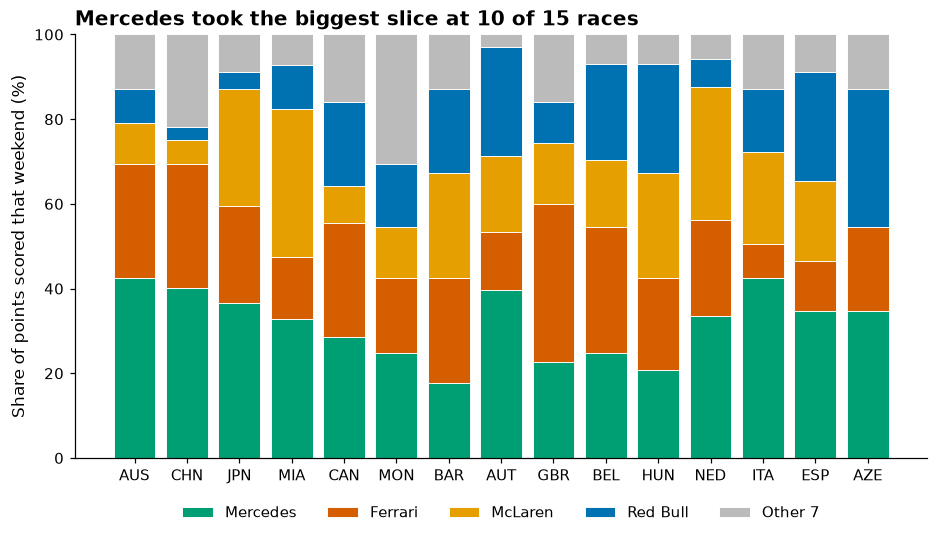

In [6]:
wide = ts.pivot(index="round", columns="team", values="points")
per_round = wide.diff().fillna(wide.iloc[0])
share = per_round.div(per_round.sum(axis=1), axis=0) * 100
share["Other 7"] = share.drop(columns=list(TOP4)).sum(axis=1)
share = share[list(TOP4) + ["Other 7"]]

fig, ax = plt.subplots(figsize=(10, 5))
bottom = np.zeros(len(share))
for team in share.columns:
    c = TOP4.get(team, GRAY)
    ax.bar(range(len(share)), share[team], bottom=bottom,
           color=c, width=0.8, label=team, edgecolor="white",
           lw=0.6)
    bottom += share[team].values
ax.set_xticks(range(len(share)), ABBR)
ax.set(ylabel="Share of points scored that weekend (%)",
       title="Mercedes took the biggest slice at 10 of 15 races",
       ylim=(0, 100))
ax.legend(ncol=5, frameon=False, loc="upper center",
          bbox_to_anchor=(0.5, -0.08))
save(fig, "fig09_proportions_points_share")
plt.show()

In [7]:
biggest = share.drop(columns="Other 7").idxmax(axis=1)
print(biggest.value_counts())
print("Mercedes average share %",
      share["Mercedes"].mean().round(1))

Mercedes    10
Ferrari      3
McLaren      1
Red Bull     1
Name: count, dtype: int64
Mercedes average share % 31.8


**Result:** Mercedes took the biggest share at 10 of 15 weekends,
about 32% of all points on average. McLaren's best weekends were
Miami (35%) and the Netherlands (31%), then zero at Azerbaijan. Red
Bull got stronger in the second half (33% at Azerbaijan). "Other 7" is
usually a thin gray band, except Monaco and China.

**Inference:** stacked bars let us compare the *same* team across
15 races, which 15 pie charts could not.

## 5.4 x-y relationship: does where you start decide where you end?

Grid and finish are paired numbers in the same unit (positions), so
a scatter with an x = y line, as the lecture recommends for paired
data. Below the line = gained places. Finishers only. Small jitter,
since positions are whole numbers and would stack on top of each
other.

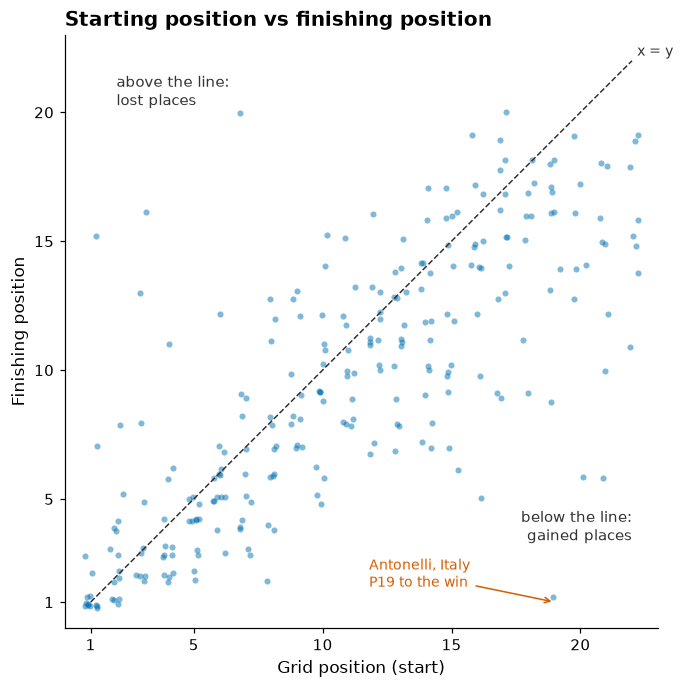

In [8]:
fin = res.dropna(subset=["finish"]).copy()
rng = np.random.default_rng(2)
jx = fin["grid"] + rng.uniform(-.25, .25, len(fin))
jy = fin["finish"] + rng.uniform(-.25, .25, len(fin))

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(jx, jy, s=16, color=OKABE_ITO["blue"], alpha=0.5, lw=0)
ax.plot([1, 22], [1, 22], color=DARK, lw=1, ls="dashed")
ax.text(2, 21.5, "above the line:\nlost places", va="top",
        fontsize=10, color=DARK)
ax.text(22, 3.4, "below the line:\ngained places", ha="right",
        fontsize=10, color=DARK)
ax.text(22.2, 22.2, "x = y", fontsize=9, color=DARK)
ita = fin[(fin["code"] == "ANT") & (fin["round"] == 13)].iloc[0]
ax.annotate("Antonelli, Italy\nP19 to the win",
            (ita["grid"], ita["finish"]), xytext=(11.8, 1.6),
            color=OKABE_ITO["red"], fontsize=9,
            arrowprops=dict(arrowstyle="->",
                            color=OKABE_ITO["red"]))
ax.set(xlabel="Grid position (start)",
       ylabel="Finishing position",
       xlim=(0, 23), ylim=(0, 23), aspect="equal",
       title="Starting position vs finishing position")
ax.set_xticks([1, 5, 10, 15, 20])
ax.set_yticks([1, 5, 10, 15, 20])
save(fig, "fig10_xy_grid_vs_finish")
plt.show()

In [9]:
rho, _ = stats.spearmanr(fin["grid"], fin["finish"])
pole = res[res["grid"] == 1]
print("Spearman rho", round(rho, 2), "| n =", len(fin))
print("pole sitter won", (pole["finish"] == 1).sum(), "of",
      len(pole))
print("share within 2 places of grid",
      ((fin["grid"] - fin["finish"]).abs() <= 2).mean().round(2))

Spearman rho 0.78 | n = 264
pole sitter won 10 of 15
share within 2 places of grid 0.61


**Result:** points hug the x = y line (Spearman rho = 0.78). The
pole sitter won 10 of 15 races, and 61% of finishers ended within
2 places of where they started. The spread gets wider further back.

**Inference:** qualifying matters a lot at the front and less at
the back, where retirements ahead shuffle the order. Antonelli's
Italy win from P19 is the big exception.

## 5.5 Geospatial: where is the calendar?

Circuits are points, not areas, so a dot map rather than a
choropleth. Robinson projection (Lecture 3's balance of area and
shape). Raced circuits are colored by the winning team, using the
same colors as 02; upcoming races are hollow gray. The HTML version
is interactive (hover for winner and date).

In [10]:
win_team = (res[res["finish"] == 1].set_index("round")["team"])
cal["win_team"] = cal["round"].map(win_team)
cal["label"] = cal["round"].astype(str) + ". " + cal["gp"]

fig = go.Figure()
groups = [(t, cal[cal["win_team"] == t]) for t in TOP4] + \
         [("Upcoming", cal[~cal["raced"]])]
for name, g in groups:
    if g.empty:
        continue
    up = name == "Upcoming"
    hover = np.where(g["raced"],
                     "Won by " + g["winner"].fillna(""),
                     "Upcoming, " + g["date"])
    fig.add_trace(go.Scattergeo(
        lat=g["lat"], lon=g["lon"], name=name,
        text=g["label"] + "<br>" + g["circuit"] + "<br>" + hover,
        hoverinfo="text", mode="markers",
        marker=dict(size=11, color="white" if up else TOP4[name],
                    line=dict(width=2,
                              color="#888888" if up else "white")),
    ))
fig.update_geos(projection_type="robinson", showcountries=True,
                countrycolor="#DDDDDD", landcolor="#F4F4F4",
                showocean=True, oceancolor="#FFFFFF",
                coastlinecolor="#CCCCCC", showframe=False)
fig.update_layout(
    title="2026 calendar: 15 races run, 8 to go",
    legend=dict(title="Race won by", orientation="h", y=-0.02),
    margin=dict(l=10, r=10, t=50, b=10), width=1000, height=560,
    font=dict(family="Arial"))
fig.write_html(FIGS / "fig11_geo_calendar_map.html",
               include_plotlyjs="cdn")
fig.write_image(FIGS / "fig11_geo_calendar_map.png", scale=2)
fig.show()

In [11]:
cal.groupby("country").size().sort_values(ascending=False).head(4)

country
United States of America    3
Spain                       2
Austria                     1
United Kingdom              1
dtype: int64

**Result:** Mercedes (green) won on every continent visited so far.
Ferrari and McLaren only won in Europe. 9 of the first 15 races
were in Europe; the season now heads to Asia, the Americas and the
Middle East.

**Inference:** the map answers "where" questions (calendar spread,
who wins where) that no bar chart can. The interactive HTML adds
details on hover without cluttering the static version.

## 5.6 Uncertainty: which team has the quickest pit stops?

From 5.2, the track sets most of the pit time. So we compare each
stop to the average stop at the same race ("seconds slower than
an average stop there"), then average per team. Each dot is a team
mean, each bar its 95% confidence interval. A wide bar means we
cannot really tell.

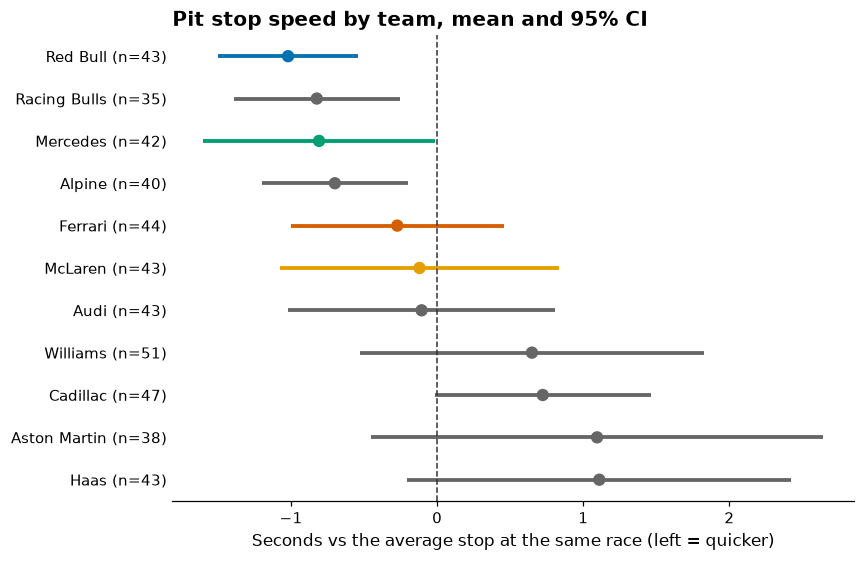

In [12]:
pit["vs_avg"] = pit["seconds"] - pit.groupby("round")[
    "seconds"].transform("mean")

def ci95(s):
    m, se = s.mean(), stats.sem(s)
    h = se * stats.t.ppf(0.975, len(s) - 1)
    return pd.Series({"mean": m, "lo": m - h, "hi": m + h,
                      "n": len(s)})

team_ci = (pit.groupby("team")["vs_avg"].apply(ci95)
              .unstack().sort_values("mean", ascending=False))

fig, ax = plt.subplots(figsize=(8, 5.5))
y = np.arange(len(team_ci))
colors = [TOP4.get(t, "#666666") for t in team_ci.index]
ax.hlines(y, team_ci["lo"], team_ci["hi"], colors=colors, lw=2.5)
ax.scatter(team_ci["mean"], y, color=colors, s=50, zorder=3)
ax.axvline(0, color=DARK, lw=1, ls="dashed")
ax.set_yticks(y, [f"{t} (n={n:.0f})" for t, n in
                  zip(team_ci.index, team_ci["n"])])
ax.set(xlabel="Seconds vs the average stop at the same race "
              "(left = quicker)",
       title="Pit stop speed by team, mean and 95% CI")
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
save(fig, "fig12_uncertainty_pit_ci")
plt.show()

In [13]:
team_ci.round(2)

,mean,lo,hi,n
team,,,,
Haas,1.11,-0.20,2.42,43.0
Aston Martin,1.09,-0.45,2.64,38.0
Cadillac,0.72,-0.02,1.46,47.0
Williams,0.65,-0.53,1.83,51.0
Audi,-0.11,-1.02,0.81,43.0
McLaren,-0.12,-1.08,0.84,43.0
Ferrari,-0.27,-1.00,0.46,44.0
Alpine,-0.70,-1.20,-0.20,40.0
Mercedes,-0.81,-1.60,-0.02,42.0


**Result:** Red Bull, Racing Bulls and Alpine are the only teams
clearly quicker than average (intervals entirely left of 0), Red
Bull by about 1 s a stop. Mercedes' interval just touches 0. For
most teams the interval crosses 0, so we cannot say they are
faster or slower than average.

**Inference:** without the error bars you would rank all 11 teams
and read meaning into a 0.1 s gap. The bars show that only the
ends of the ranking are real.

## Takeaways for Lecture 5

| Family | Chart | Question it answered |
|---|---|---|
| Amounts | sorted bars | who has the most points |
| Distributions | box + strip | how long pit stops take |
| Proportions | 100% stacked bars | who took the points each race |
| x-y | scatter + x = y line | does the grid decide the result |
| Geospatial | dot map | where races are and who won them |
| Uncertainty | mean + 95% CI | which pit crews are really faster |

The chart type follows from the data type and the question.